# 1a. Avaliação da disciplina Modelagem Matemática com Aplicação de Inteligência Artificial.

Aplicação de PCA e LASSO à série temporal ERA5 de ondas e ventos (1985–1994).

Pergunta: quais informações de ondas e ventos ajudam a prever a altura significativa das ondas (Hs) com 24 horas de antecedência?

O ERA5 é a quinta geração do modelo de reanálise atmosférica do Centro Europeu para Previsões Meteorológicas de Médio Alcance (ECMWF6), que fornece estimativas de variáveis climáticas atmosféricas, terrestres e oceânicas. O processo de reanálise consiste na utilização de um modelo climático que assimila dados de observações globais, para produzir uma base de dados climatológicas multidecadal.

No contexto deste trabalho foram utizados dados de ondas (Hs, T e Dir) e ventos (u e v) coletados numa estação offshore. Os dados de onda correspondem a altura significativa da onda, período e direção, respectivamente. Já "u" e "v" são componentes do vento, de leste e norte, respectivamente, que se deslocam 10 metros acima da superfície. Ainda sobre essas variáveis calculou-se a velocidade do vento (velocidade = √u²+v²) e a direção para qual sopra (dir (°) = (270-(arctang2(v,u))x(180/π))).


1. Leitura do arquivo

In [1]:
from google.colab import files
from io import BytesIO
import pandas as pd

# Execute esta célula e selecione o arquivo Excel (.xlsx) do ERA5.
arquivos = files.upload()

if len(arquivos) != 1:
    raise ValueError('Selecione apenas um arquivo Excel do ERA5 e execute a célula novamente.')

nome_arquivo = next(iter(arquivos))

# Lê diretamente o arquivo selecionado, sem caminho fixo ou acesso ao Drive.
df = pd.read_excel(BytesIO(arquivos[nome_arquivo]))
print(f'Arquivo carregado: {nome_arquivo}')


Saving saida_completa_ecmwf_itaguai_1985-1994.xlsx to saida_completa_ecmwf_itaguai_1985-1994.xlsx
Arquivo carregado: saida_completa_ecmwf_itaguai_1985-1994.xlsx


In [2]:
# Converte a coluna Data para formato Datetime e define como índice temporal
df['Data'] = pd.to_datetime(df['Data'], format='%d/%m/%Y %H:%M:%S')
df = df.set_index('Data')

# Exibe as primeiras linhas para confirmar a leitura
df.head()

,u10,v10,Velocidade_vento,Direcao_vento,Hs,Tp,Dir
Data,,,,,,,
1985-01-01 00:00:00,2.419418,-1.055252,2.639534,293.564880,0.985610,8.665382,112.390884
1985-01-01 06:00:00,2.060532,0.883026,2.241768,246.802795,0.904096,8.513527,112.494797
1985-01-01 12:00:00,2.663940,2.699005,3.792256,224.625397,0.843441,8.408058,115.437714
1985-01-01 18:00:00,5.098328,4.345490,6.698972,229.557846,0.917987,8.162941,131.719193
1985-01-02 00:00:00,3.138901,3.252182,4.519888,223.984543,0.974068,7.940285,139.274521


2. Plotagem da localizaçõ da estação do ERA5 offshore

In [3]:
!pip install cartopy -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 76.0 MB/s eta 0:00:00


In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces_lakes.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


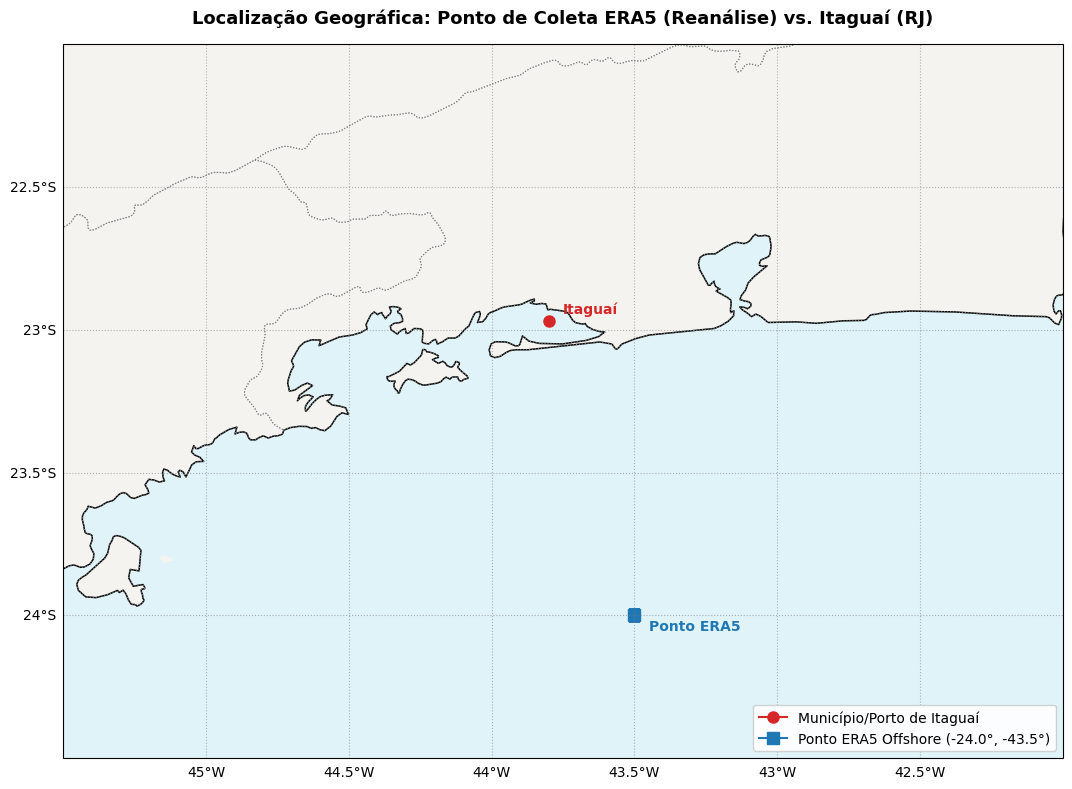

In [5]:
# =========================================================
# COORDENADAS DO PONTO DO ERA5
# =========================================================
era5_lat = -24.00  # Exemplo de Latitude do ponto ERA5 offshore
era5_lon = -43.50  # Exemplo de Longitude do ponto ERA5 offshore

# Coordenada de referência para o Porto/Município de Itaguaí
itaguai_lat = -22.97
itaguai_lon = -43.80

# ---------------------------------------------------------
# CONSTRUÇÃO DO MAPA GEOGRÁFICO
# ---------------------------------------------------------
fig = plt.figure(figsize=(12, 8))

# Projeção Cartográfica PlateCarree
ax = plt.axes(projection=ccrs.PlateCarree())

# Configuração dos limites do mapa (no Sudeste / Baía de Sepetiba e mar aberto)
ax.set_extent([-45.5, -42.0, -24.5, -22.0], crs=ccrs.PlateCarree())

# Adiciona elementos geográficos (Terra, Oceano, Linha de Costa e Fronteiras dos Estados)
ax.add_feature(cfeature.LAND, facecolor='#f4f3f0', edgecolor='none')
ax.add_feature(cfeature.OCEAN, facecolor='#e0f3f8')
ax.add_feature(cfeature.COASTLINE, linewidth=1.1, edgecolor='black')
ax.add_feature(
    cfeature.STATES, linestyle=':', linewidth=0.8, edgecolor='gray'
)

# ---------------------------------------------------------
# PLOTAGEM DOS PONTOS DE INTERESSE
# ---------------------------------------------------------
# Ponto 1: Município de Itaguaí (Terra)
ax.plot(
    itaguai_lon,
    itaguai_lat,
    marker='o',
    color='#d62728',
    markersize=8,
    transform=ccrs.PlateCarree(),
    label='Município/Porto de Itaguaí',
)
ax.text(
    itaguai_lon + 0.05,
    itaguai_lat + 0.03,
    'Itaguaí',
    fontsize=10,
    fontweight='bold',
    color='#d62728',
    transform=ccrs.PlateCarree(),
)

# Ponto 2: Célula de Grade do ERA5 (Offshore)
ax.plot(
    era5_lon,
    era5_lat,
    marker='s',
    color='#1f77b4',
    markersize=9,
    transform=ccrs.PlateCarree(),
    label=f'Ponto ERA5 Offshore ({era5_lat}°, {era5_lon}°)',
)
ax.text(
    era5_lon + 0.05,
    era5_lat - 0.05,
    'Ponto ERA5',
    fontsize=10,
    fontweight='bold',
    color='#1f77b4',
    transform=ccrs.PlateCarree(),
)


# ---------------------------------------------------------
# ELEMENTOS DE GRID E LEGENDA
# ---------------------------------------------------------
gl = ax.gridlines(
    draw_labels=True, linestyle=':', color='gray', alpha=0.6
)
gl.top_labels = False
gl.right_labels = False

plt.title(
    'Localização Geográfica: Ponto de Coleta ERA5 (Reanálise) vs. Itaguaí (RJ)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

3. Análise Preliminar e Plotagem dos dados(Gráficos e Métricas)

In [25]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns

In [7]:
# Configurações estéticas dos gráficos
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

In [8]:
# CRIAÇÃO DAS VARIÁVEIS DE SAZONALIDADE E PERCENTIL 90
df['month'] = df.index.month
df['year'] = df.index.year

# Separação Sazonal (Verão Extensivo: Nov-Abr vs Inverno Extensivo: Mai-Out)
df['season'] = np.where(
    df['month'].isin([5, 6, 7, 8, 9, 10]), 'Inverno (Mai-Out)', 'Verão (Nov-Abr)'
)

# Valor que representa os 10% maiores estados de mar (Percentil 90)
hs_10_percent = df['Hs'].quantile(0.90)

print('=' * 60)
print(f'MÉTRICAS PRELIMINARES DE Hs (1985 - 1994):')
print(f'-> Média de Hs: {df["Hs"].mean():.2f} metros')
print(f'-> Máximo de Hs: {df["Hs"].max():.2f} metros')
print(
    f'-> Limiar dos 10% maiores estados de mar (P90): {hs_10_percent:.2f} metros'
)
print('=' * 60)

MÉTRICAS PRELIMINARES DE Hs (1985 - 1994):
-> Média de Hs: 1.51 metros
-> Máximo de Hs: 4.66 metros
-> Limiar dos 10% maiores estados de mar (P90): 2.16 metros


In [9]:
!pip install windrose

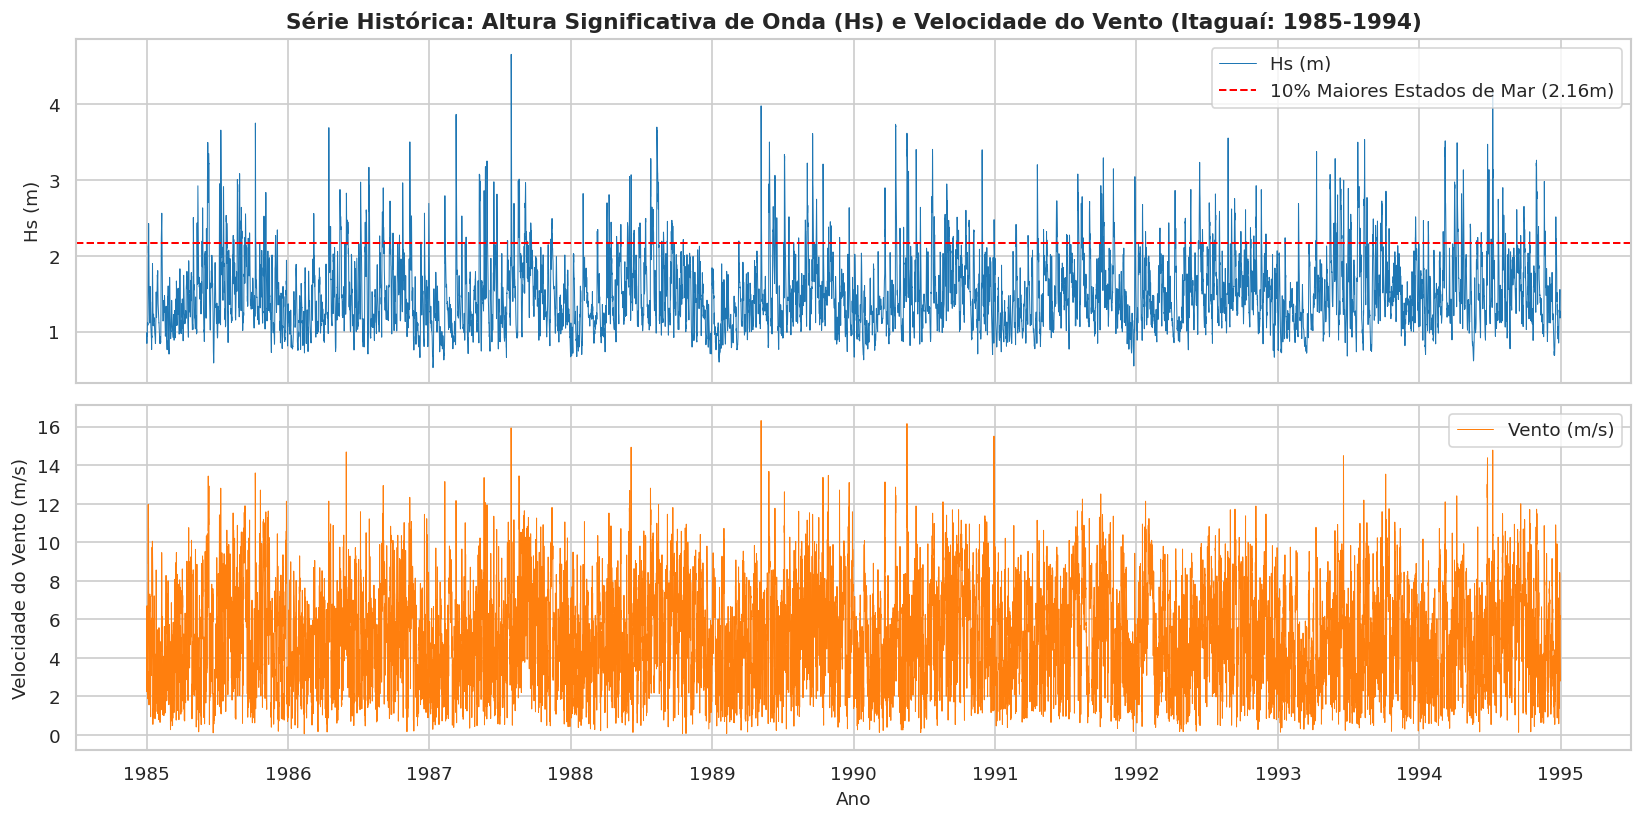

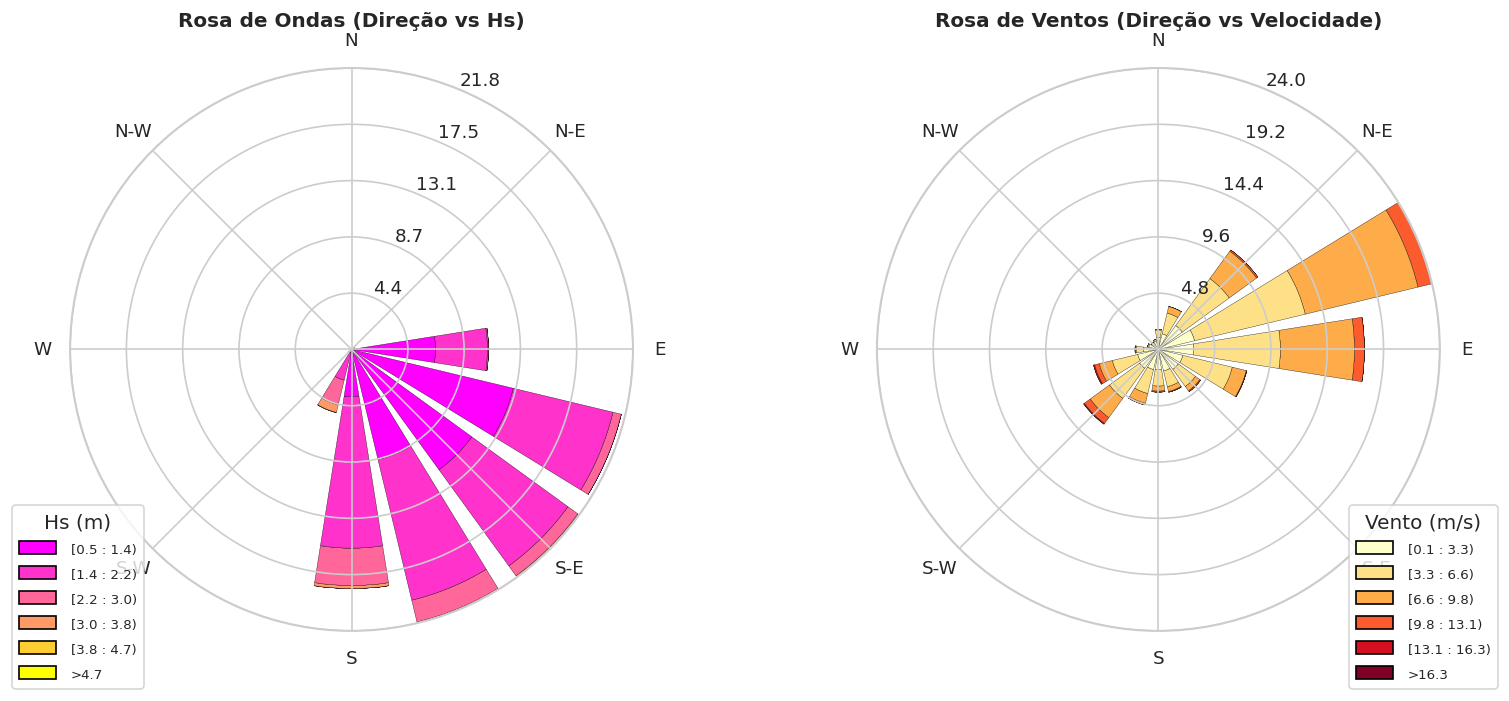

In [10]:
from windrose import WindroseAxes
# GRÁFICO: SÉRIE HISTÓRICA COMPLETA (Hs e Vento)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Painel Superior: Hs
axes[0].plot(df.index, df['Hs'], color='#1f77b4', lw=0.6, label='Hs (m)')
axes[0].axhline(
    hs_10_percent,
    color='red',
    linestyle='--',
    linewidth=1.2,
    label=f'10% Maiores Estados de Mar ({hs_10_percent:.2f}m)',
)
axes[0].set_ylabel('Hs (m)', fontsize=11)
axes[0].set_title(
    'Série Histórica: Altura Significativa de Onda (Hs) e Velocidade do Vento'
    ' (Itaguaí: 1985-1994)',
    fontsize=13,
    fontweight='bold',
)
axes[0].legend(loc='upper right')

# Painel Inferior: Velocidade do Vento
axes[1].plot(
    df.index,
    df['Velocidade_vento'],
    color='#ff7f0e',
    lw=0.6,
    label='Vento (m/s)',
)
axes[1].set_ylabel('Velocidade do Vento (m/s)', fontsize=11)
axes[1].set_xlabel('Ano', fontsize=11)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# GRÁFICOS: ROSAS DE ONDAS E VENTOS
# ---------------------------------------------------------
fig = plt.figure(figsize=(14, 6))

# --- ROSA DE ONDAS (Direção da Onda vs Hs) ---
ax1 = fig.add_subplot(121, projection='windrose')
ax1.bar(
    df['Dir'],
    df['Hs'],
    normed=True,
    opening=0.8,
    edgecolor='black',
    linewidth=0.2,
    cmap=plt.cm.spring,
)
ax1.set_title(
    'Rosa de Ondas (Direção vs Hs)', fontsize=12, fontweight='bold', pad=25
)
ax1.set_legend(title='Hs (m)', loc='lower left', bbox_to_anchor=(-0.1, -0.1))

# --- ROSA DE VENTOS (Direção do Vento vs Velocidade) ---
ax2 = fig.add_subplot(122, projection='windrose')
ax2.bar(
    df['Direcao_vento'],
    df['Velocidade_vento'],
    normed=True,
    opening=0.8,
    edgecolor='black',
    linewidth=0.2,
    cmap=plt.cm.YlOrRd,
)
ax2.set_title(
    'Rosa de Ventos (Direção vs Velocidade)',
    fontsize=12,
    fontweight='bold',
    pad=25,
)
ax2.set_legend(
    title='Vento (m/s)', loc='lower right', bbox_to_anchor=(1.1, -0.1)
)

plt.tight_layout()
plt.show()

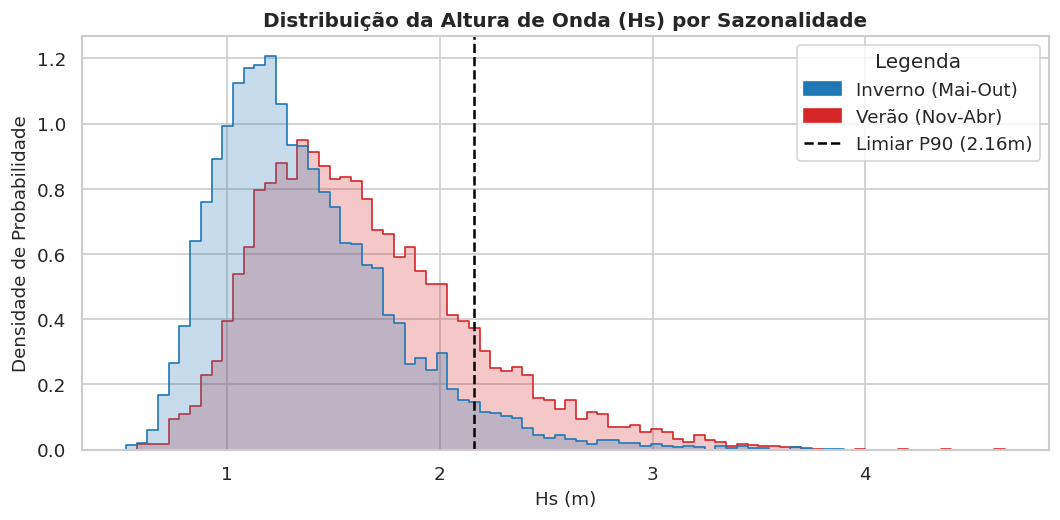

In [11]:
#GRÁFICO: DISTRIBUIÇÃO SAZONAL DE Hs (Inverno vs Verão)
plt.figure(figsize=(9, 4.5))

# Plot do Histograma
ax = sns.histplot(
    data=df,
    x='Hs',
    hue='season',
    element='step',
    stat='density',
    common_norm=False,
    palette=['#1f77b4', '#d62728'],
)

# Linha do Percentil 90
plt.axvline(
    hs_10_percent,
    color='black',
    linestyle='--',
    linewidth=1.5,
)

# Elementos da Legenda
# retângulos coloridos correspondentes às cores da palette
patch_inverno = mpatches.Patch(color='#1f77b4', label='Inverno (Mai-Out)')
patch_verao = mpatches.Patch(color='#d62728', label='Verão (Nov-Abr)')

# Cria a linha tracejada preta para o P90
line_p90 = plt.Line2D(
    [0],
    [0],
    color='black',
    linestyle='--',
    linewidth=1.5,
    label=f'Limiar P90 ({hs_10_percent:.2f}m)',
)

# Aplicação da legenda combinada
plt.legend(
    handles=[patch_inverno, patch_verao, line_p90],
    loc='upper right',
    title='Legenda',
)

plt.title(
    'Distribuição da Altura de Onda (Hs) por Sazonalidade',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Hs (m)', fontsize=11)
plt.ylabel('Densidade de Probabilidade', fontsize=11)

plt.tight_layout()
plt.show()

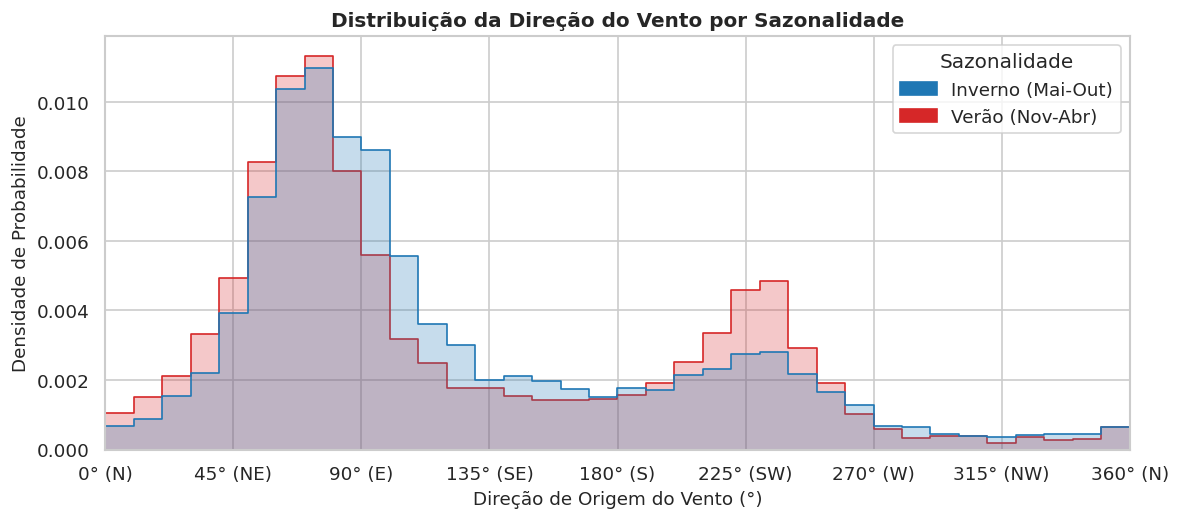

In [12]:
#GRÁFICO: DISTRIBUIÇÃO SAZONAL DO VENTO (Inverno vs Verão)
plt.figure(figsize=(10, 4.5))

# Histograma / Densidade para a Direção do Vento ('Direcao_vento')
ax = sns.histplot(
    data=df,
    x='Direcao_vento',
    hue='season',
    element='step',
    stat='density',
    common_norm=False,
    bins=36,  # Bins de 10 graus (360 / 36) para boa resolução angular
    palette=['#1f77b4', '#d62728'],
)

# Elementos da Legenda
patch_inverno = mpatches.Patch(color='#1f77b4', label='Inverno (Mai-Out)')
patch_verao = mpatches.Patch(color='#d62728', label='Verão (Nov-Abr)')

plt.legend(
    handles=[patch_inverno, patch_verao],
    loc='upper right',
    title='Sazonalidade',
)

# Formatação Geográfica do Eixo X (Graus e Pontos Cardeais)
plt.xlim(0, 360)
plt.xticks(
    ticks=[0, 45, 90, 135, 180, 225, 270, 315, 360],
    labels=[
        '0° (N)',
        '45° (NE)',
        '90° (E)',
        '135° (SE)',
        '180° (S)',
        '225° (SW)',
        '270° (W)',
        '315° (NW)',
        '360° (N)',
    ],
)

plt.title(
    'Distribuição da Direção do Vento por Sazonalidade',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Direção de Origem do Vento (°)', fontsize=11)
plt.ylabel('Densidade de Probabilidade', fontsize=11)

plt.tight_layout()
plt.show()

/tmp/ipykernel_2085/2701467725.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='month', y='Hs', palette='Blues_d')


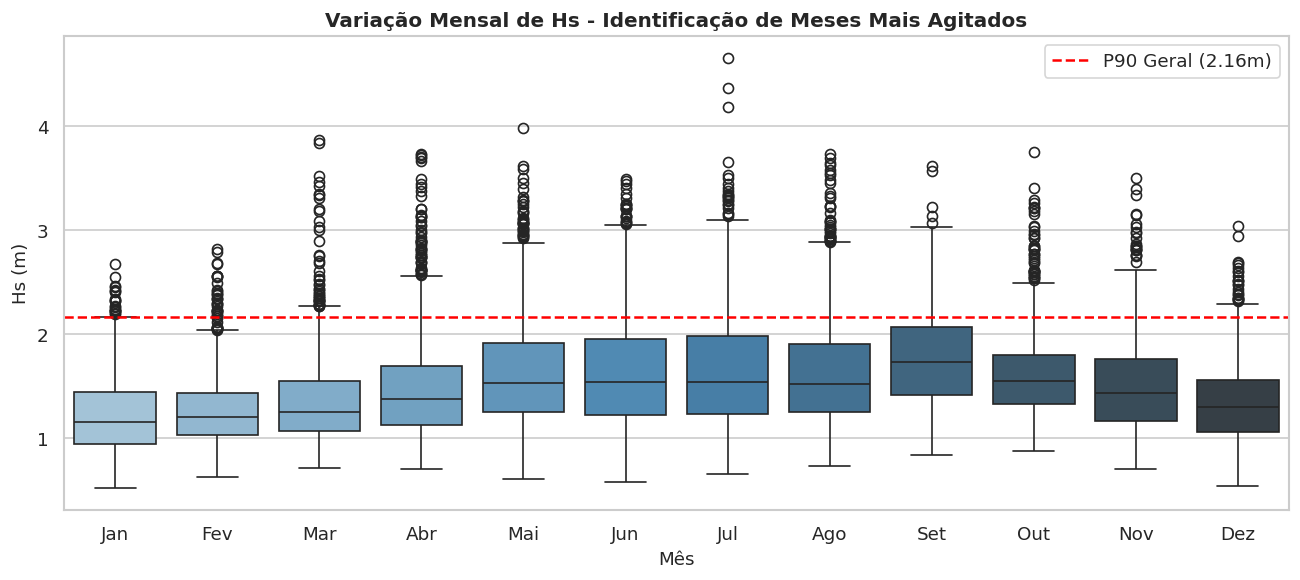

In [13]:
# GRÁFICO: VARIAÇÃO MENSAL DA ONDA (BOXPLOT)
plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x='month', y='Hs', palette='Blues_d')
plt.axhline(
    hs_10_percent,
    color='red',
    linestyle='--',
    label=f'P90 Geral ({hs_10_percent:.2f}m)',
)
plt.title(
    'Variação Mensal de Hs - Identificação de Meses Mais Agitados',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Mês', fontsize=11)
plt.ylabel('Hs (m)', fontsize=11)
plt.xticks(
    ticks=range(12),
    labels=[
        'Jan',
        'Fev',
        'Mar',
        'Abr',
        'Mai',
        'Jun',
        'Jul',
        'Ago',
        'Set',
        'Out',
        'Nov',
        'Dez',
    ],
)
plt.legend()
plt.tight_layout()
plt.show()

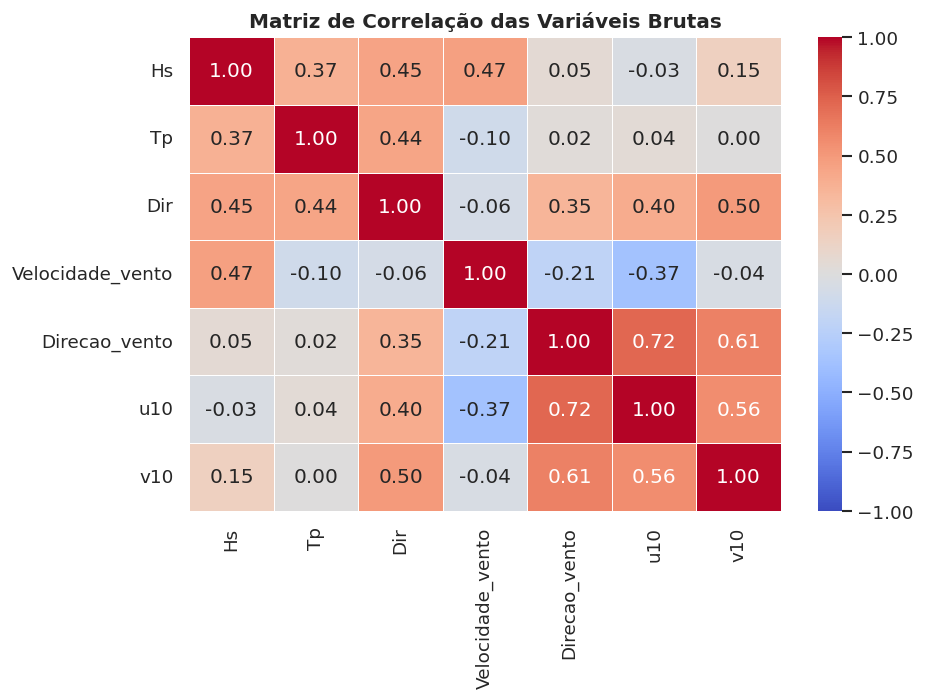

In [26]:
# GRÁFICO: MATRIZ DE CORRELAÇÃO
plt.figure(figsize=(8, 6))
cols_corr = ['Hs', 'Tp', 'Dir', 'Velocidade_vento', 'Direcao_vento', 'u10', 'v10']
corr = df[cols_corr].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title(
    'Matriz de Correlação das Variáveis Brutas', fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()

4. Preparação para a previsão
O alvo será Hs 24 horas no futuro. Como a série tem intervalo de 6 horas, 24 horas correspondem a quatro registros. As direções são convertidas em seno e cosseno porque 0° e 360° representam a mesma direção.

In [15]:
import numpy as np
import pandas as pd

In [27]:
# TRANSFORMAÇÃO TRIGONOMÉTRICA (SENO E COSSENO)
# Para a direção das Ondas (Dir)
df['sin_wave_dir'] = np.sin(np.radians(df['Dir']))
df['cos_wave_dir'] = np.cos(np.radians(df['Dir']))

# Para a direção do Vento (Direcao_vento)
df['sin_wind_dir'] = np.sin(np.radians(df['Direcao_vento']))
df['cos_wind_dir'] = np.cos(np.radians(df['Direcao_vento']))

In [28]:
# CRIAÇÃO DAS VARIÁVEIS DE ATRASO (LAGS)
# ---------------------------------------------------------
# Como os dados são a cada 6h: colunas de histórico (lags de 6h, 12h, 24h)
# - Lag 1 = 6 horas atrás
# - Lag 2 = 12 horas atrás
# - Lag 4 = 24 horas atrás
# Definir a coluna do Hs de 24h no futuro como a nossa coluna alvo

# Lags da Altura Significativa de Onda (Hs)
df['Hs_lag6h'] = df['Hs'].shift(1)
df['Hs_lag12h'] = df['Hs'].shift(2)
df['Hs_lag24h'] = df['Hs'].shift(4)

# Lags do Período da Onda (Tp)
df['Tp_lag6h'] = df['Tp'].shift(1)
df['Tp_lag12h'] = df['Tp'].shift(2)
df['Tp_lag24h'] = df['Tp'].shift(4)

# Lags da Velocidade do Vento
df['wind_speed_lag6h'] = df['Velocidade_vento'].shift(1)
df['wind_speed_lag12h'] = df['Velocidade_vento'].shift(2)
df['wind_speed_lag24h'] = df['Velocidade_vento'].shift(4)

In [18]:
# ESTATÍSTICAS MÓVEIS (JANELA DAS ÚLTIMAS 24 HORAS)
# Média e valor máximo das últimas 24h (janela de 4 registros de 6h)
df['Hs_mean_24h'] = df['Hs'].rolling(window=4).mean()
df['Hs_max_24h'] = df['Hs'].rolling(window=4).max()

df['wind_mean_24h'] = df['Velocidade_vento'].rolling(window=4).mean()
df['wind_max_24h'] = df['Velocidade_vento'].rolling(window=4).max()

In [19]:
# DEFINIÇÃO DA VARIÁVEL ALVO (TARGET: Hs em t + 24 horas)
# Queremos prever o Hs 24h à frente -> shift de -4 passos no tempo
df['target_Hs_24h'] = df['Hs'].shift(-4)

In [20]:
# REMOÇÃO DE LINHAS COM VALORES NULOS (NaNs)
# ---------------------------------------------------------
df_model = df.dropna().copy()

# Impressão dos resultados para verificação
print("Total de registros brutos:", len(df))
print("Total de registros prontos para modelagem:", len(df_model))
print("\nNovas colunas criadas:")

colunas_visualizar = [
    'sin_wave_dir',
    'cos_wave_dir',
    'Hs_lag6h',
    'Hs_mean_24h',
    'target_Hs_24h',
]
print(df_model[colunas_visualizar].head())

Total de registros brutos: 14608
Total de registros prontos para modelagem: 14600

Novas colunas criadas:
                     sin_wave_dir  cos_wave_dir  Hs_lag6h  Hs_mean_24h  \
Data                                                                     
1985-01-02 00:00:00      0.652435     -0.757844  0.917987     0.909898   
1985-01-02 06:00:00      0.775914     -0.630839  0.974068     0.918654   
1985-01-02 12:00:00      0.802017     -0.597301  0.939119     0.946996   
1985-01-02 18:00:00      0.719906     -0.694072  0.956810     0.981298   
1985-01-03 00:00:00      0.654084     -0.756422  1.055193     1.016173   

                     target_Hs_24h  
Data                                
1985-01-02 00:00:00       1.113572  
1985-01-02 06:00:00       1.087895  
1985-01-02 12:00:00       1.114893  
1985-01-02 18:00:00       1.110328  
1985-01-03 00:00:00       1.083768  


5. Separação temporal
Os primeiros 80% dos registros são usados para treinamento e os últimos 20% para teste. A ordem temporal é preservada para evitar o uso de informações futuras no treinamento.

In [29]:
from sklearn.preprocessing import StandardScaler

# 1. Separar Variáveis Explicativas (X) da Variável Alvo (y)
colunas_excluir = ['target_Hs_24h', 'month', 'year', 'season']
features_col = [col for col in df_model.columns if col not in colunas_excluir]

X = df_model[features_col]
y = df_model['target_Hs_24h']

# 2. Divisão Temporal Estrita (80% Treino / 20% Teste)
split_idx = int(len(df_model) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

# 3. Padronização dos Dados (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Linhas para Treinamento (80%): {X_train.shape[0]}")
print(f"Linhas para Teste (20%): {X_test.shape[0]}")
print(f"Número total de variáveis explicativas (Features): {X_train.shape[1]}")

Linhas para Treinamento (80%): 11680
Linhas para Teste (20%): 2920
Número total de variáveis explicativas (Features): 24


6. PCA: Redução da dimensionalidade

O PCA cria componentes que combinam as variáveis originais. O número de componentes é escolhido para explicar pelo menos 90% da variância dos preditores.

In [30]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# =========================================================
# MODELO DE PERSISTÊNCIA (BASELINE)
# =========================================================
# A persistência prevê y(t+24h) assumindo o valor de Hs no instante atual t
# A coluna 'Hs' atual está no conjunto X (sem padronização)
y_pred_persist = X_test['Hs']

mae_persist = mean_absolute_error(y_test, y_pred_persist)
rmse_persist = np.sqrt(mean_squared_error(y_test, y_pred_persist))
r2_persist = r2_score(y_test, y_pred_persist)


# =========================================================
# ANÁLISE DE COMPONENTES PRINCIPAIS (PCA) + REGRESSÃO
# =========================================================
# Mantém componentes suficientes para explicar 95% da variância dos dados
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Ajusta a Regressão Linear nos componentes principais
lr_pca = LinearRegression()
lr_pca.fit(X_train_pca, y_train)

y_pred_pca = lr_pca.predict(X_test_pca)

mae_pca = mean_absolute_error(y_test, y_pred_pca)
rmse_pca = np.sqrt(mean_squared_error(y_test, y_pred_pca))
r2_pca = r2_score(y_test, y_pred_pca)

print('--- RESULTADOS PARCIAIS ---')
print(
    f'PCA reduziu as {X_train.shape[1]} variáveis para'
    f' {pca.n_components_} Componentes Principais.'
)
print(f'Variância Total Explicada pelo PCA: {sum(pca.explained_variance_ratio_)*100:.2f}%')
print(
    f'\nPersistência -> MAE: {mae_persist:.3f}m | RMSE: {rmse_persist:.3f}m |'
    f' R²: {r2_persist:.3f}'
)
print(
    f'PCA + OLS     -> MAE: {mae_pca:.3f}m | RMSE: {rmse_pca:.3f}m | R²:'
    f' {r2_pca:.3f}'
)

--- RESULTADOS PARCIAIS ---
PCA reduziu as 24 variáveis para 11 Componentes Principais.
Variância Total Explicada pelo PCA: 95.81%

Persistência -> MAE: 0.309m | RMSE: 0.432m | R²: 0.285
PCA + OLS     -> MAE: 0.278m | RMSE: 0.382m | R²: 0.439


7. LASSO: seleção de variáveis

O LASSO penaliza os coeficientes e pode reduzir alguns deles a zero. O parâmetro de penalização é escolhido por validação cruzada própria para séries temporais.

In [23]:
# =========================================================
# REGRESSÃO LASSO (SELEÇÃO DE VARIÁVEIS)
# =========================================================
# alpha controla a força da regularização (penalidade L1)
lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = lasso.predict(X_test_scaled)

mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)


# =========================================================
# TABELA COMPARATIVA DE DESEMPENHO
# =========================================================
df_resultados = pd.DataFrame(
    {
        'Modelo': ['Persistência (Baseline)', 'PCA + Regressão Linear', 'LASSO'],
        'MAE (m)': [mae_persist, mae_pca, mae_lasso],
        'RMSE (m)': [rmse_persist, rmse_pca, rmse_lasso],
        'R²': [r2_persist, r2_pca, r2_lasso],
    }
)

print('=========================================================')
print('           DESEMPENHO DOS MODELOS NO CONJUNTO DE TESTE    ')
print('=========================================================')
print(df_resultados.to_string(index=False))

# =========================================================
# VARIÁVEIS SELECIONADAS PELO LASSO
# =========================================================
coef_df = pd.DataFrame(
    {'Variável': features_col, 'Coeficiente': lasso.coef_}
).sort_values(by='Coeficiente', key=abs, ascending=False)

print('\n--- IMPORTÂNCIA DAS VARIÁVEIS NO LASSO ---')
print(coef_df.to_string(index=False))

           DESEMPENHO DOS MODELOS NO CONJUNTO DE TESTE    
                 Modelo  MAE (m)  RMSE (m)       R²
Persistência (Baseline) 0.308529  0.431733 0.284614
 PCA + Regressão Linear 0.278439  0.382415 0.438720
                  LASSO 0.267654  0.372378 0.467797

--- IMPORTÂNCIA DAS VARIÁVEIS NO LASSO ---
         Variável  Coeficiente
               Hs     0.290132
              v10     0.042413
        Hs_lag12h    -0.041604
     sin_wave_dir    -0.033411
               Tp     0.033298
     sin_wind_dir    -0.026344
 Velocidade_vento     0.022842
wind_speed_lag12h    -0.003155
        Tp_lag24h    -0.002494
              Dir     0.000000
              u10     0.000000
    Direcao_vento     0.000000
         Hs_lag6h    -0.000000
        Hs_lag24h    -0.000000
     cos_wind_dir    -0.000000
     cos_wave_dir    -0.000000
        Tp_lag12h    -0.000000
         Tp_lag6h    -0.000000
 wind_speed_lag6h    -0.000000
wind_speed_lag24h    -0.000000
      Hs_mean_24h    -0.000000
       

8. Comparação das Previsões

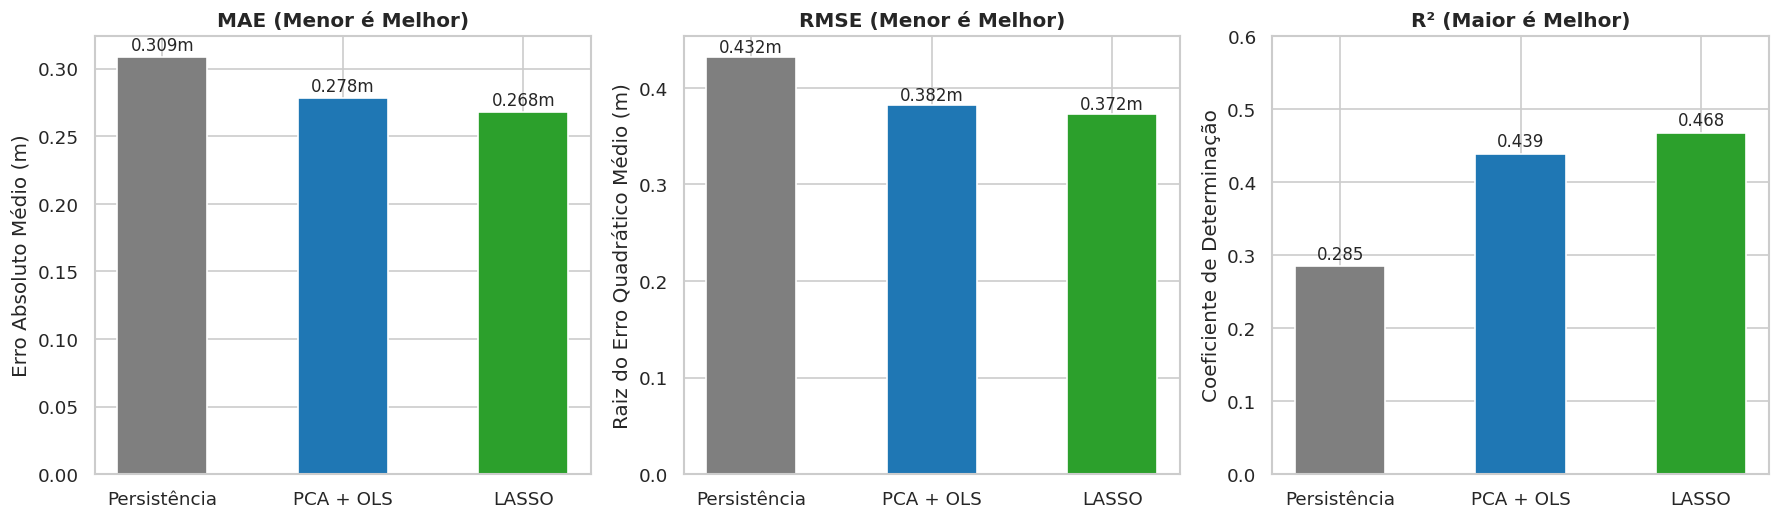

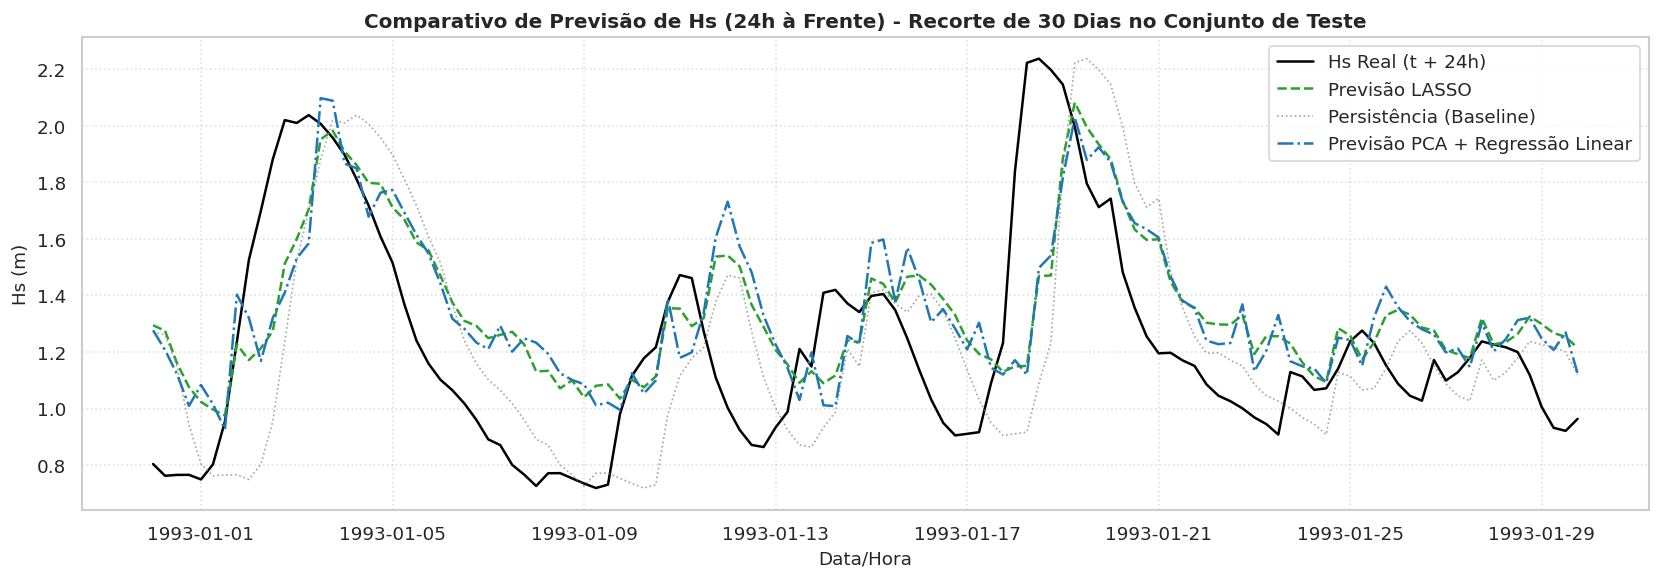

In [34]:
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# GRÁFICO DE BARRAS: COMPARAÇÃO DAS MÉTRICAS
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

modelos = ['Persistência', 'PCA + OLS', 'LASSO']
cores = ['#7f7f7f', '#1f77b4', '#2ca02c']

# MAE
axes[0].bar(modelos, df_resultados['MAE (m)'], color=cores, width=0.5)
axes[0].set_title('MAE (Menor é Melhor)', fontweight='bold')
axes[0].set_ylabel('Erro Absoluto Médio (m)')
for i, v in enumerate(df_resultados['MAE (m)']):
    axes[0].text(i, v + 0.005, f'{v:.3f}m', ha='center', fontsize=10)

# RMSE
axes[1].bar(modelos, df_resultados['RMSE (m)'], color=cores, width=0.5)
axes[1].set_title('RMSE (Menor é Melhor)', fontweight='bold')
axes[1].set_ylabel('Raiz do Erro Quadrático Médio (m)')
for i, v in enumerate(df_resultados['RMSE (m)']):
    axes[1].text(i, v + 0.005, f'{v:.3f}m', ha='center', fontsize=10)

# R²
axes[2].bar(modelos, df_resultados['R²'], color=cores, width=0.5)
axes[2].set_title('R² (Maior é Melhor)', fontweight='bold')
axes[2].set_ylabel('Coeficiente de Determinação')
axes[2].set_ylim(0, 0.6)
for i, v in enumerate(df_resultados['R²']):
    axes[2].text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# GRÁFICO DE SÉRIE TEMPORAL: REAL VS PREVISTO (LASSO)
# ---------------------------------------------------------
# Plota os primeiros 30 dias do conjunto de teste (120 passos de 6h)
n_pontos = 120

plt.figure(figsize=(14, 5))
plt.plot(
    y_test.index[:n_pontos],
    y_test.values[:n_pontos],
    label='Hs Real (t + 24h)',
    color='black',
    linewidth=1.5,
)
plt.plot(
    y_test.index[:n_pontos],
    y_pred_lasso[:n_pontos],
    label='Previsão LASSO',
    color='#2ca02c',
    linestyle='--',
    linewidth=1.5,
)
plt.plot(
    y_test.index[:n_pontos],
    y_pred_persist[:n_pontos],
    label='Persistência (Baseline)',
    color='#7f7f7f',
    linestyle=':',
    linewidth=1.0,
    alpha=0.7,
)
plt.plot(
    y_test.index[:n_pontos],
    y_pred_pca[:n_pontos],
    label='Previsão PCA + Regressão Linear',
    color='#1f77b4',
    linestyle='-.',
    linewidth=1.5,
)

plt.title(
    'Comparativo de Previsão de Hs (24h à Frente) - Recorte de 30 Dias no'
    ' Conjunto de Teste',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Data/Hora', fontsize=11)
plt.ylabel('Hs (m)', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()



DESEMPENHO DOS MODELOS — PREVISÃO DE 12h
                Modelo  MAE (m)  RMSE (m)    R²
          Persistência    0.190     0.275 0.710
PCA + Regressão Linear    0.195     0.271 0.719
                 LASSO    0.175     0.248 0.763


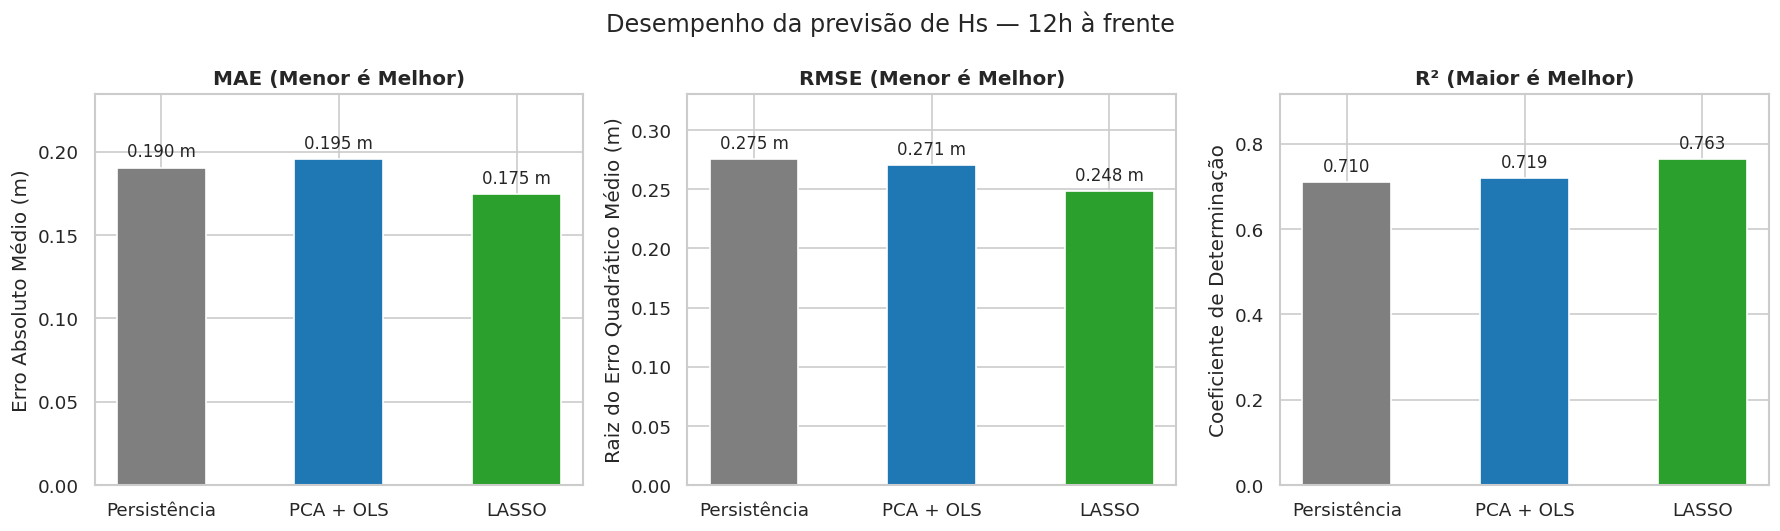

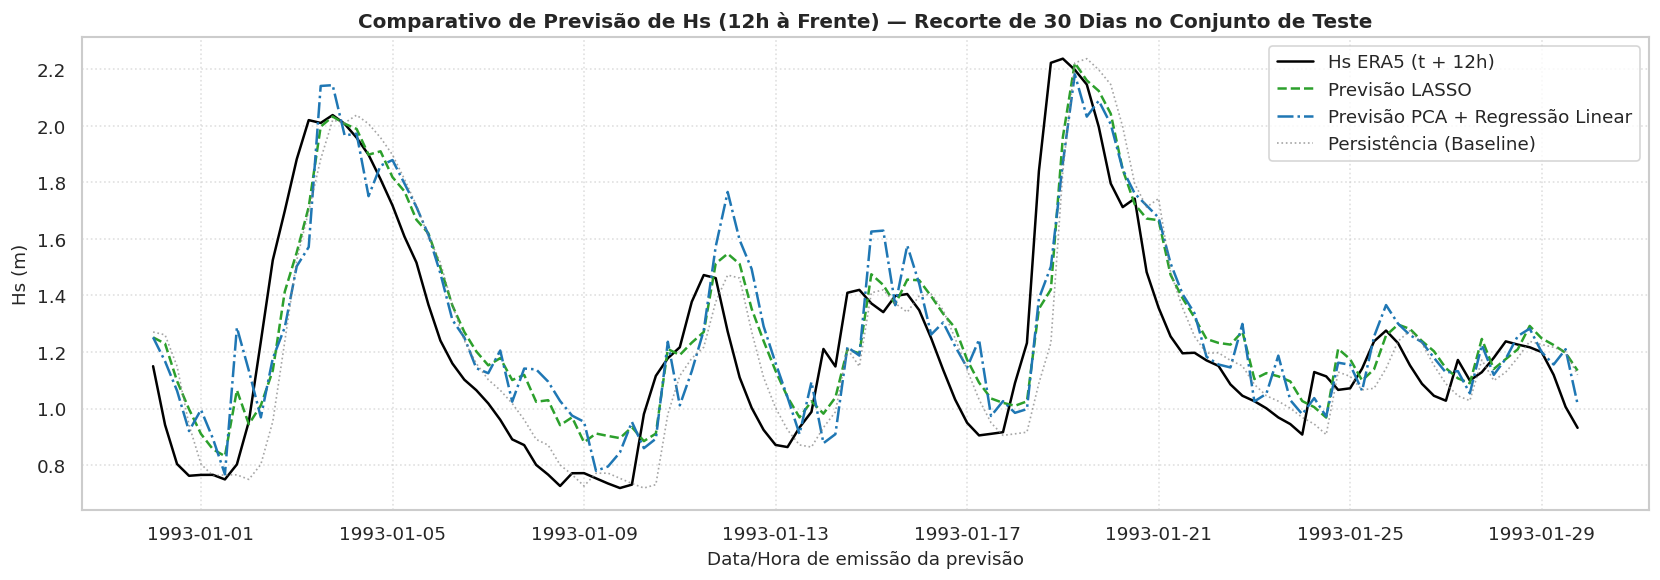

In [33]:
# PREVISÃO DE Hs COM 12 HORAS DE ANTECEDÊNCIA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Lasso

# Mesmas variáveis explicativas da análise de 24h
X_12h = df[features_col].copy()
y_12h = df['Hs'].shift(-2)

validos = X_12h.notna().all(axis=1) & y_12h.notna()
X_12h = X_12h.loc[validos]
y_12h = y_12h.loc[validos]

# Mantém a mesma data de início do teste da análise de 24h.
# Exclui do treino alvos que já estejam no período de teste.
inicio_teste = X_test.index[0]
datas_alvo = X_12h.index + pd.Timedelta(hours=12)

treino = datas_alvo < inicio_teste
teste = X_12h.index >= inicio_teste

X_train_12h = X_12h.loc[treino]
X_test_12h = X_12h.loc[teste]
y_train_12h = y_12h.loc[treino]
y_test_12h = y_12h.loc[teste]

# Padronização
scaler_12h = StandardScaler()
X_train_scaled_12h = scaler_12h.fit_transform(X_train_12h)
X_test_scaled_12h = scaler_12h.transform(X_test_12h)

# PCA + regressão linear
pca_12h = PCA(n_components=0.95)
X_train_pca_12h = pca_12h.fit_transform(X_train_scaled_12h)
X_test_pca_12h = pca_12h.transform(X_test_scaled_12h)

lr_12h = LinearRegression()
lr_12h.fit(X_train_pca_12h, y_train_12h)
y_pred_pca_12h = lr_12h.predict(X_test_pca_12h)

# LASSO
lasso_12h = Lasso(alpha=0.01, random_state=42)
lasso_12h.fit(X_train_scaled_12h, y_train_12h)
y_pred_lasso_12h = lasso_12h.predict(X_test_scaled_12h)

# Persistência: assume que o Hs atual continuará igual em 12h
y_pred_persist_12h = X_test_12h['Hs'].to_numpy()

# TABELA DE ERROS — PREVISÃO DE 12h
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

previsoes_12h = {
    'Persistência': y_pred_persist_12h,
    'PCA + Regressão Linear': y_pred_pca_12h,
    'LASSO': y_pred_lasso_12h,
}

df_resultados_12h = pd.DataFrame([
    {
        'Modelo': nome,
        'MAE (m)': mean_absolute_error(y_test_12h, previsao),
        'RMSE (m)': np.sqrt(
            mean_squared_error(y_test_12h, previsao)
        ),
        'R²': r2_score(y_test_12h, previsao),
    }
    for nome, previsao in previsoes_12h.items()
])

print('DESEMPENHO DOS MODELOS — PREVISÃO DE 12h')
print(
    df_resultados_12h.to_string(
        index=False, float_format=lambda x: f'{x:.3f}'
    )
)

# GRÁFICOS DE BARRAS: COMPARAÇÃO DAS MÉTRICAS
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

modelos = ['Persistência', 'PCA + OLS', 'LASSO']
cores = ['#7f7f7f', '#1f77b4', '#2ca02c']

metricas = [
    ('MAE (m)', 'MAE (Menor é Melhor)', 'Erro Absoluto Médio (m)'),
    ('RMSE (m)', 'RMSE (Menor é Melhor)',
     'Raiz do Erro Quadrático Médio (m)'),
    ('R²', 'R² (Maior é Melhor)', 'Coeficiente de Determinação'),
]

for ax, (coluna, titulo, rotulo) in zip(axes, metricas):
    valores = df_resultados_12h[coluna].to_numpy()
    barras = ax.bar(modelos, valores, color=cores, width=0.5)

    ax.set_title(titulo, fontweight='bold')
    ax.set_ylabel(rotulo)
    ax.axhline(0, color='black', linewidth=0.6)

    # Limites automáticos: também mostram R² negativo.
    inferior = min(0, valores.min())
    superior = max(0, valores.max())
    margem = max(superior - inferior, 0.01) * 0.20
    ax.set_ylim(
        inferior - margem if inferior < 0 else 0,
        superior + margem,
    )

    sufixo = ' m' if coluna != 'R²' else ''
    ax.bar_label(
        barras,
        labels=[f'{v:.3f}{sufixo}' for v in valores],
        padding=4,
        fontsize=10,
    )

fig.suptitle('Desempenho da previsão de Hs — 12h à frente')
plt.tight_layout()
plt.show()

# Gráfico: primeiros 30 dias do teste
n_pontos = min(120, len(y_test_12h))
datas = y_test_12h.index[:n_pontos]

plt.figure(figsize=(14, 5))

plt.plot(
    datas, y_test_12h.values[:n_pontos],
    label='Hs ERA5 (t + 12h)',
    color='black', linewidth=1.5,
)
plt.plot(
    datas, y_pred_lasso_12h[:n_pontos],
    label='Previsão LASSO',
    color='#2ca02c', linestyle='--', linewidth=1.5,
)
plt.plot(
    datas, y_pred_pca_12h[:n_pontos],
    label='Previsão PCA + Regressão Linear',
    color='#1f77b4', linestyle='-.', linewidth=1.5,
)
plt.plot(
    datas, y_pred_persist_12h[:n_pontos],
    label='Persistência (Baseline)',
    color='#7f7f7f', linestyle=':', linewidth=1.0, alpha=0.7,
)

plt.title(
    'Comparativo de Previsão de Hs (12h à Frente) — '
    'Recorte de 30 Dias no Conjunto de Teste',
    fontsize=12, fontweight='bold',
)
plt.xlabel('Data/Hora de emissão da previsão', fontsize=11)
plt.ylabel('Hs (m)', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()